In [22]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import warnings


warnings.filterwarnings("ignore", message=".*inplace keyword.*")

t = yf.Ticker("FCNTX")
adj = t.history(start="2015-01-01", auto_adjust=True)["Close"]
raw = t.history(start="2015-01-01", auto_adjust=False)["Close"]

print(len(adj), adj.index.min().date(), adj.index.max().date())
adj.head()

2980 2015-01-02 2026-11-06


Date
2015-01-02 00:00:00-05:00    4.804191
2015-01-05 00:00:00-05:00    4.717244
2015-01-06 00:00:00-05:00    4.667629
2015-01-07 00:00:00-05:00    4.725594
2015-01-08 00:00:00-05:00    4.809594
Name: Close, dtype: float64

In [23]:
ret = adj.pct_change().dropna()
ret.describe()

count    2979.000000
mean        0.000642
std         0.012072
min        -0.118084
25%        -0.004429
50%         0.001036
75%         0.006752
max         0.097682
Name: Close, dtype: float64

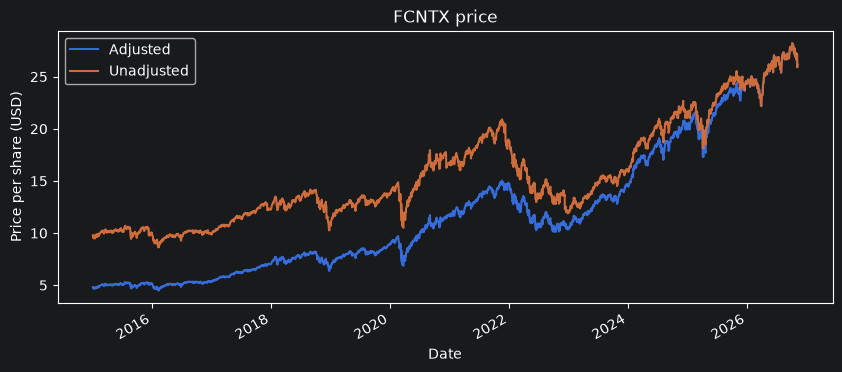

In [24]:
ax = adj.plot(label="Adjusted", figsize=(10, 4))
raw.plot(ax=ax, label="Unadjusted")
ax.legend()
ax.set_title("FCNTX price")
ax.set_xlabel("Date")
ax.set_ylabel("Price per share (USD)")
plt.show()

In [25]:
# Adjusted Price
first_adj = adj.iloc[0]
last_adj = adj.iloc[-1]
print(first_adj, last_adj)

# Raw Price
first_raw = raw.iloc[0]
last_raw = raw.iloc[-1]
print(first_raw, last_raw)

total_adj = (last_adj / first_adj) - 1
print(f"Adjusted total return: {total_adj:.1%}")

total_raw = (last_raw / first_raw) - 1
print(f"Raw total return: {total_raw:.1%}")

# Adjusted return shows what the investor actually +457% taking into account
# (Payables including Dividends and capital gain distributions)
# comparison to +174% of raw return which is just the displayed price change



4.804190635681152 26.149999618530273
9.779999732971191 26.149999618530273
Adjusted total return: 444.3%
Raw total return: 167.4%


In [26]:
daily_mean = ret.mean()
daily_std = ret.std()
print(daily_mean, daily_std)

# Total trading days is 252 days * daily return
annual_return = 252 * daily_mean
# Variance = vol squared
annual_vol = daily_std * (252 ** 0.5)
print(f"Total annual return: {annual_return:.1%}")
print(f"Annual Vol: {annual_vol:.1%}")

years = ((adj.index[-1] - adj.index[0]).days / 365.25)
print(1.164 ** years - 1)


0.0006420153169442017 0.01207248760366446
Total annual return: 16.2%
Annual Vol: 19.2%
5.041479509852385


In [27]:
CAGR = ((last_adj / first_adj) ** (1/years)) - 1
print(f"CAGR: {CAGR:.1%}")

CAGR: 15.4%


Date
2026-11-02 00:00:00-05:00    28.209999
2026-11-03 00:00:00-05:00    28.209999
2026-11-04 00:00:00-05:00    28.209999
2026-11-05 00:00:00-05:00    28.209999
2026-11-06 00:00:00-05:00    28.209999
Name: Close, dtype: float64


<function matplotlib.pyplot.show(close=None, block=None)>

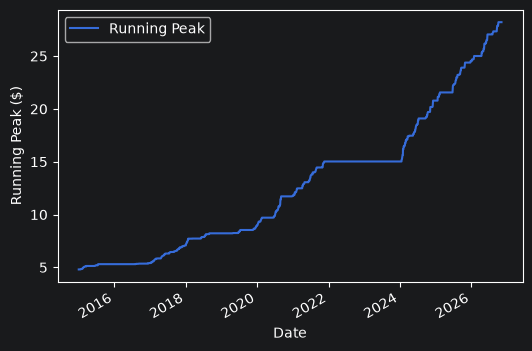

In [28]:
# Running Peak
peak = adj.cummax()
print(peak.tail())
ax = peak.plot(label="Running Peak", figsize=(6, 4))
ax.set_ylabel("Running Peak ($)")
ax.set_xlabel("Date")
ax.legend()
plt.show


Date
2026-11-02 00:00:00-05:00   -0.057781
2026-11-03 00:00:00-05:00   -0.050691
2026-11-04 00:00:00-05:00   -0.036157
2026-11-05 00:00:00-05:00   -0.081886
2026-11-06 00:00:00-05:00   -0.073024
Name: Close, dtype: float64
Current Drawdown: -7.3%
max drawdown: -32.6% on 2022-09-30


<function matplotlib.pyplot.show(close=None, block=None)>

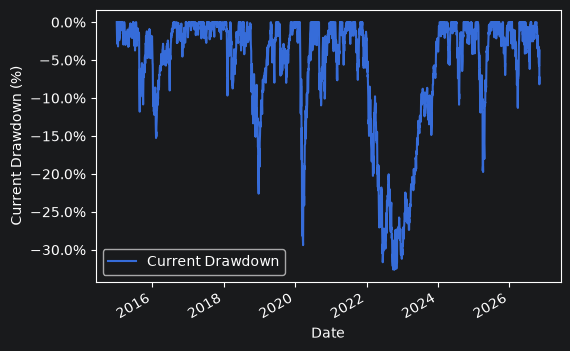

In [29]:
# Drawdown
drawdown = adj / peak - 1
worst_drawdown = drawdown.min()
worst_drawdown_date = drawdown.idxmin().date()
print(drawdown.tail())
print(f"Current Drawdown: {drawdown.iloc[-1]:.1%}")
print(f"max drawdown: {worst_drawdown:.1%} on {worst_drawdown_date}")

ax = drawdown.plot(label="Current Drawdown", figsize=(6, 4))

from matplotlib.ticker import PercentFormatter
ax.yaxis.set_major_formatter(PercentFormatter(1.0))


ax.set_ylabel("Current Drawdown (%)")
ax.set_xlabel("Date")
ax.legend()
plt.show


In [30]:
info = yf.Ticker("FCNTX").info
print(info.keys())

funds = pd.read_csv("../config/funds.csv")
funds.head()

names = []
fees = []


for t in funds["ticker"]:
    info = yf.Ticker(t).info
    names.append(info.get("longName"))
    fees.append(info.get("netExpenseRatio"))
    print(t)

print(names)
print(fees)

funds["name"] = names
funds["expense_ratio"] = pd.Series(fees) / 100
funds.to_csv("../config/funds.csv", index=False)


dict_keys(['address1', 'address2', 'address3', 'phone', 'longBusinessSummary', 'companyOfficers', 'executiveTeam', 'maxAge', 'priceHint', 'previousClose', 'regularMarketPreviousClose', 'averageVolume', 'averageVolume10days', 'averageDailyVolume10Day', 'yield', 'ytdReturn', 'totalAssets', 'fiftyTwoWeekLow', 'fiftyTwoWeekHigh', 'allTimeHigh', 'allTimeLow', 'fulldayPrice', 'fulldayChange', 'fulldayChangePercent', 'fiftyDayAverage', 'twoHundredDayAverage', 'currency', 'tradeable', 'morningStarOverallRating', 'morningStarRiskRating', 'annualReportExpenseRatio', 'beta3Year', 'fundInceptionDate', 'lastDividendValue', 'lastCapGain', 'annualHoldingsTurnover', 'quoteType', 'symbol', 'language', 'region', 'typeDisp', 'quoteSourceName', 'triggerable', 'customPriceAlertConfidence', 'exchange', 'shortName', 'longName', 'twoHundredDayAverageChange', 'twoHundredDayAverageChangePercent', 'netExpenseRatio', 'sourceInterval', 'exchangeDataDelayedBy', 'cryptoTradeable', 'marketState', 'corporateActions', 

In [30]:
import os
import pandas as pd

path = "../config/funds.csv"
print("Saving to:", os.path.abspath(path))

funds = pd.read_csv(path)
print("Columns before:", list(funds.columns))

funds = funds.drop(columns=["Unnamed: 0"])
funds["expense_ratio"] = funds["expense_ratio"].round(6)
funds.to_csv(path, index=False)

print("Columns after:", list(funds.columns))
funds

In [38]:
from pandas_datareader import data as pdr

ff5 = pdr.DataReader("F-F_Research_Data_5_Factors_2x3_daily", "famafrench", start="2015-01-01")
print(ff5.keys())
print(ff5[0].head())
print(ff5[0].columns)

mom = pdr.DataReader("F-F_Momentum_factor_Daily", "famafrench", start="2015-01-01")
print(mom.keys())
print(mom[0].head())
print(mom[0].columns)
# Momentum End dates
print(ff5[0].index.max(), mom[0].index.max())

ff = ff5[0] / 100
m = mom[0] / 100
factors = ff.join(m, how="inner")
print(factors.shape)
print(factors.head())
print(factors.tail())

dict_keys([0, 'DESCR'])
            Mkt-RF   SMB   HML   RMW   CMA   RF
Date                                           
2015-01-02   -0.12 -0.56  0.12 -0.28  0.15  0.0
2015-01-05   -1.84  0.24 -0.68  0.17 -0.08  0.0
2015-01-06   -1.03 -0.79 -0.29  0.52  0.06  0.0
2015-01-07    1.19  0.17 -0.67  0.26 -0.17  0.0
2015-01-08    1.81 -0.10 -0.29  0.10 -0.21  0.0
Index(['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF'], dtype='str')
dict_keys([0, 'DESCR'])
             Mom
Date            
2015-01-02 -0.08
2015-01-05  1.15
2015-01-06  0.49
2015-01-07  0.97
2015-01-08  0.14
Index(['Mom'], dtype='str')
2026-09-30 2026-09-30
(2953, 7)
            Mkt-RF     SMB     HML     RMW     CMA   RF     Mom
Date                                                           
2015-01-02 -0.0012 -0.0056  0.0012 -0.0028  0.0015  0.0 -0.0008
2015-01-05 -0.0184  0.0024 -0.0068  0.0017 -0.0008  0.0  0.0115
2015-01-06 -0.0103 -0.0079 -0.0029  0.0052  0.0006  0.0  0.0049
2015-01-07  0.0119  0.0017 -0.0067  0.0026 -0.0017  

In [41]:
r = pd.read_csv("../data/raw/rates.csv")
f = pd.read_csv("../data/raw/factors.csv")
print(r.tail(3))
print(f[["date", "RF"]].tail(3))
print(r[r["date"] == "2026-09-30"])
print(f[f["date"] == "2026-09-30"]["RF"].values)

            date  DTB3  rf_daily
2961  2026-11-04  4.03  0.000160
2962  2026-11-05  4.00  0.000159
2963  2026-11-06  4.01  0.000159
            date      RF
2950  2026-09-28  0.0001
2951  2026-09-29  0.0001
2952  2026-09-30  0.0001
            date  DTB3  rf_daily
2937  2026-09-30  4.03   0.00016
[0.0001]


In [42]:
r = pd.read_csv("../data/raw/rates.csv", parse_dates=["date"])
print(r[r["rf_daily"] < 0])

           date  DTB3      rf_daily
180  2015-09-18 -0.01 -3.968254e-07
182  2015-09-22 -0.01 -3.968254e-07
185  2015-09-25 -0.01 -3.968254e-07
188  2015-09-30 -0.01 -3.968254e-07
189  2015-10-01 -0.02 -7.936508e-07
194  2015-10-08 -0.01 -3.968254e-07
1307 2020-03-25 -0.04 -1.587302e-06
1308 2020-03-26 -0.05 -1.984127e-06
